In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

### Statisical estimation

In [2]:
# Mesoproterozoic candidate spherules
Helena_size = np.array([
    23.7, 20.0, 19.7, 21.8, 31.3,
    26.0, 24.8, 19.4, 28.8, 24.8,
    25.5, 15.6, 26.3, 18.8, 26.3,
    27.7, 40.0, 54.0, 117.0, 77.0,
    54.0, 46.8, 65.3, 65.5, 48.0
])

# Modern Antarctic cosmic spherules: Genge et al. (2017)
Genge_dia_MET = np.load('Genge_MET.npy')

Genge_dia_OX = np.load('Genge_OX.npy')

Genge_size = np.concatenate((Genge_dia_MET, Genge_dia_OX))
print(len(Genge_dia_MET))
print(len(Genge_dia_OX))
# Devonian cosmic spherules: Ruggiu et al.
Ruggiu_size = np.array([
    18.5, 19.3, 20.5, 21.4, 26.1, 27.6, 28.7, 30.9,
    32.7, 34.3, 36.2, 38.0, 39.5, 41.1, 43.5, 45.3,
    47.5, 49.0, 51.0, 54.4, 57.0, 61.8, 65.9, 69.1,
    73.6, 76.6, 82.3, 86.3, 92.0, 96.4, 99.5, 104.3,
    109.4, 117.5, 122.3, 129.3, 130.2, 135.4, 136.4,
    140.8, 140.7, 147.6, 151.1, 152.2, 154.6, 168.7,
    187.1, 191.4, 210.4, 350.2
])
print(len(Ruggiu_size))
Rudraswami_size = np.array([
    83, 118, 89, 79, 117, 89, 124, 148, 112, 128, 100,
    83, 157, 162, 254, 234, 208, 221, 100, 120, 107, 112,
    99, 119, 352, 276,
])

Suttle_size = np.array([
    107, 111, 137, 118, 178, 95, 75, 40,
    44, 39, 33, 47, 40, 128, 157, 225, 269,
    66, 169, 137])

36
38
50


In [10]:
for i in range(len(Genge_size)):
    print(Genge_size[i])

47.804878048780495
57.07317073170732
61.46341463414636
63.41463414634147
66.82926829268294
68.04878048780488
69.51219512195122
70.48780487804879
70.73170731707317
74.14634146341463
78.04878048780488
82.19512195121952
83.41463414634147
90.97560975609757
91.70731707317073
97.31707317073172
97.31707317073172
97.56097560975608
98.04878048780488
101.70731707317073
103.41463414634147
109.51219512195122
109.02439024390246
110.24390243902438
111.21951219512196
118.53658536585367
120.24390243902438
121.46341463414633
125.60975609756098
129.2682926829268
131.46341463414632
136.58536585365857
143.1707317073171
146.58536585365852
151.46341463414637
174.6341463414634
64.63414634146343
71.46341463414635
75.1219512195122
76.09756097560977
77.8048780487805
86.09756097560977
86.82926829268293
87.56097560975611
98.29268292682927
101.21951219512194
102.92682926829268
106.09756097560974
107.56097560975608
112.19512195121952
111.95121951219512
116.34146341463416
118.53658536585367
119.26829268292683
120.24

In [4]:
def describe_size(data, name="Dataset"):
    """
    Print descriptive statistics for a particle-size distribution.
    """
    data = np.asarray(data, dtype=float)
    data = data[np.isfinite(data)]

    q1, median, q3 = np.percentile(data, [25, 50, 75])

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(f"N               = {len(data)}")
    print(f"Mean            = {np.mean(data):.2f} µm")
    print(f"SD              = {np.std(data, ddof=1):.2f} µm")
    print(f"Minimum         = {np.min(data):.2f} µm")
    print(f"Maximum         = {np.max(data):.2f} µm")
    print(f"Median          = {median:.2f} µm")
    print(f"Q1              = {q1:.2f} µm")
    print(f"Q3              = {q3:.2f} µm")
    print(f"IQR             = {q3-q1:.2f} µm")
    print(f"N < 50 µm       = {np.sum(data < 50)} "
          f"({100*np.mean(data < 50):.1f}%)")

    print(f"N < 80 µm       = {np.sum(data < 80)} "
          f"({100*np.mean(data < 80):.1f}%)")


describe_size(Helena_size, "Mesoproterozoic candidates")
describe_size(Ruggiu_size, "Devonian - Ruggiu")
describe_size(Genge_size, "Modern Antarctic - Genge")
describe_size(Suttle_size, "Miocene - Suttle")
describe_size(Rudraswami_size, "Modern Indian Ocean")



Mesoproterozoic candidates
N               = 25
Mean            = 37.92 µm
SD              = 23.68 µm
Minimum         = 15.60 µm
Maximum         = 117.00 µm
Median          = 26.30 µm
Q1              = 23.70 µm
Q3              = 48.00 µm
IQR             = 24.30 µm
N < 50 µm       = 19 (76.0%)
N < 80 µm       = 24 (96.0%)

Devonian - Ruggiu
N               = 50
Mean            = 90.91 µm
SD              = 64.50 µm
Minimum         = 18.50 µm
Maximum         = 350.20 µm
Median          = 75.10 µm
Q1              = 39.90 µm
Q3              = 134.10 µm
IQR             = 94.20 µm
N < 50 µm       = 18 (36.0%)
N < 80 µm       = 26 (52.0%)

Modern Antarctic - Genge
N               = 74
Mean            = 110.53 µm
SD              = 31.64 µm
Minimum         = 47.80 µm
Maximum         = 186.83 µm
Median          = 110.73 µm
Q1              = 86.28 µm
Q3              = 130.18 µm
IQR             = 43.90 µm
N < 50 µm       = 1 (1.4%)
N < 80 µm       = 16 (21.6%)

Miocene - Suttle
N               = 2

In [5]:
# ============================================================
# 3. BOOTSTRAP CONFIDENCE INTERVAL FOR MEDIAN
# ============================================================

def bootstrap_median_ci(data, n_boot=100_000, confidence=0.95, seed=42):
    """
    Percentile bootstrap confidence interval for the median.
    """
    data = np.asarray(data, dtype=float)
    data = data[np.isfinite(data)]

    rng = np.random.default_rng(seed)

    boot_medians = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(data, size=len(data), replace=True)
        boot_medians[i] = np.median(sample)

    alpha = (1 - confidence) / 2

    lower = np.quantile(boot_medians, alpha)
    upper = np.quantile(boot_medians, 1 - alpha)

    return np.median(data), lower, upper


print("\n\nBOOTSTRAP 95% CI FOR MEDIANS")
print("=" * 60)

datasets = {
    "Mesoproterozoic": Helena_size,
    "Devonian": Ruggiu_size,
    "Modern": Genge_size,
    "Modern MET": Genge_dia_MET,
    "Modern OX": Genge_dia_OX
}

for name, data in datasets.items():

    med, low, high = bootstrap_median_ci(data)

    print(
        f"{name:20s}: "
        f"median = {med:.2f} µm "
        f"(95% CI: {low:.2f}–{high:.2f})"
    )


# ============================================================
# 4. BOOTSTRAP MEDIAN RATIO
# ============================================================

def bootstrap_median_ratio(
        numerator,
        denominator,
        n_boot=100_000,
        confidence=0.95,
        seed=42
):
    """
    Bootstrap confidence interval for:
        median(numerator) / median(denominator)

    Example:
        modern / Mesoproterozoic
    """

    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator, dtype=float)

    numerator = numerator[np.isfinite(numerator)]
    denominator = denominator[np.isfinite(denominator)]

    rng = np.random.default_rng(seed)

    ratios = np.empty(n_boot)

    for i in range(n_boot):

        num_sample = rng.choice(
            numerator,
            size=len(numerator),
            replace=True
        )

        den_sample = rng.choice(
            denominator,
            size=len(denominator),
            replace=True
        )

        ratios[i] = (
            np.median(num_sample) /
            np.median(den_sample)
        )

    observed_ratio = (
        np.median(numerator) /
        np.median(denominator)
    )

    alpha = (1 - confidence) / 2

    lower = np.quantile(ratios, alpha)
    upper = np.quantile(ratios, 1-alpha)

    return observed_ratio, lower, upper


def print_ratio(name, numerator, denominator):

    ratio, low, high = bootstrap_median_ratio(
        numerator,
        denominator
    )

    print(
        f"{name:35s}: "
        f"{ratio:.2f} "
        f"(95% CI: {low:.2f}–{high:.2f})"
    )


print("\n\nBOOTSTRAP MEDIAN RATIOS")
print("=" * 60)

print_ratio(
    "Modern / Mesoproterozoic",
    Genge_size,
    Helena_size
)

print_ratio(
    "Devonian / Mesoproterozoic",
    Ruggiu_size,
    Helena_size
)

print_ratio(
    "Modern / Devonian",
    Genge_size,
    Ruggiu_size
)

print_ratio(
    "Modern MET / Mesoproterozoic",
    Genge_dia_MET,
    Helena_size
)

print_ratio(
    "Modern OX / Mesoproterozoic",
    Genge_dia_OX,
    Helena_size
)




BOOTSTRAP 95% CI FOR MEDIANS
Mesoproterozoic     : median = 26.30 µm (95% CI: 24.80–46.80)
Devonian            : median = 75.10 µm (95% CI: 51.00–104.45)
Modern              : median = 110.73 µm (95% CI: 101.22–120.24)
Modern MET          : median = 97.80 µm (95% CI: 83.41–110.37)
Modern OX           : median = 121.10 µm (95% CI: 109.76–128.90)


BOOTSTRAP MEDIAN RATIOS
Modern / Mesoproterozoic           : 4.21 (95% CI: 2.45–4.68)
Devonian / Mesoproterozoic         : 2.86 (95% CI: 1.57–3.97)
Modern / Devonian                  : 1.47 (95% CI: 1.04–2.21)
Modern MET / Mesoproterozoic       : 3.72 (95% CI: 2.19–4.29)
Modern OX / Mesoproterozoic        : 4.60 (95% CI: 2.62–4.99)


In [6]:
# ============================================================
# 5. TWO-SAMPLE STATISTICAL TESTS
# ============================================================

def compare_distributions(data1, data2, name1="Group 1", name2="Group 2"):
    """
    Compare two independent size distributions using:
      1. two-sided Kolmogorov-Smirnov test
      2. two-sided Mann-Whitney U test
    """

    data1 = np.asarray(data1, dtype=float)
    data2 = np.asarray(data2, dtype=float)

    data1 = data1[np.isfinite(data1)]
    data2 = data2[np.isfinite(data2)]

    # --------------------------------------------------------
    # Kolmogorov-Smirnov test
    # H0: both samples come from the same distribution
    # --------------------------------------------------------

    ks = stats.ks_2samp(
        data1,
        data2,
        alternative="two-sided",
        method="auto"
    )

    # --------------------------------------------------------
    # Mann-Whitney U test
    # H0: distributions have equal ranks
    # --------------------------------------------------------

    mw = stats.mannwhitneyu(
        data1,
        data2,
        alternative="two-sided",
        method="auto"
    )

    print("\n" + "=" * 60)
    print(f"{name1} vs {name2}")
    print("=" * 60)

    print(f"N1 = {len(data1)}, N2 = {len(data2)}")

    print("\nKolmogorov-Smirnov test")
    print(f"KS D statistic = {ks.statistic:.6f}")
    print(f"p-value        = {ks.pvalue:.6e}")

    print("\nMann-Whitney U test")
    print(f"U statistic    = {mw.statistic:.6f}")
    print(f"p-value        = {mw.pvalue:.6e}")

    return ks, mw


# Primary comparison for the manuscript
ks_modern, mw_modern = compare_distributions(
    Helena_size,
    Genge_size,
    "Mesoproterozoic",
    "Modern"
)

# Other comparisons
ks_dev, mw_dev = compare_distributions(
    Helena_size,
    Ruggiu_size,
    "Mesoproterozoic",
    "Devonian"
)

ks_mod_dev, mw_mod_dev = compare_distributions(
    Ruggiu_size,
    Genge_size,
    "Devonian",
    "Modern"
)

ks_met, mw_met = compare_distributions(
    Helena_size,
    Genge_dia_MET,
    "Mesoproterozoic",
    "Modern MET"
)

ks_ox, mw_ox = compare_distributions(
    Helena_size,
    Genge_dia_OX,
    "Mesoproterozoic",
    "Modern OX"
)


# ============================================================
# 6. EFFECT SIZE FOR MANN-WHITNEY:
#    COMMON-LANGUAGE EFFECT SIZE
# ============================================================

def probability_superiority(reference, candidate):
    """
    Probability that a randomly selected value from 'reference'
    is larger than a randomly selected value from 'candidate'.

    0.5 = no tendency
    close to 1 = reference tends to be much larger
    """

    reference = np.asarray(reference)
    candidate = np.asarray(candidate)

    greater = 0
    ties = 0

    for x in reference:
        greater += np.sum(x > candidate)
        ties += np.sum(x == candidate)

    total = len(reference) * len(candidate)

    return (greater + 0.5 * ties) / total


print("\n\nCOMMON-LANGUAGE EFFECT SIZE")
print("=" * 60)

ps = probability_superiority(
    Genge_size,
    Helena_size
)

print(
    "P(random modern diameter > random Mesoproterozoic diameter)"
    f" = {ps:.4f} ({100*ps:.1f}%)"
)


Mesoproterozoic vs Modern
N1 = 25, N2 = 74

Kolmogorov-Smirnov test
KS D statistic = 0.852432
p-value        = 6.497095e-15

Mann-Whitney U test
U statistic    = 68.000000
p-value        = 5.263966e-12

Mesoproterozoic vs Devonian
N1 = 25, N2 = 50

Kolmogorov-Smirnov test
KS D statistic = 0.480000
p-value        = 6.694028e-04

Mann-Whitney U test
U statistic    = 249.000000
p-value        = 2.439279e-05

Devonian vs Modern
N1 = 50, N2 = 74

Kolmogorov-Smirnov test
KS D statistic = 0.406486
p-value        = 6.056207e-05

Mann-Whitney U test
U statistic    = 1295.000000
p-value        = 4.735755e-03

Mesoproterozoic vs Modern MET
N1 = 25, N2 = 36

Kolmogorov-Smirnov test
KS D statistic = 0.812222
p-value        = 2.000614e-10

Mann-Whitney U test
U statistic    = 46.000000
p-value        = 3.268241e-09

Mesoproterozoic vs Modern OX
N1 = 25, N2 = 38

Kolmogorov-Smirnov test
KS D statistic = 0.893684
p-value        = 4.150291e-13

Mann-Whitney U test
U statistic    = 22.000000
p-value   

In [7]:
# ============================================================
# 7. OPTIONAL: NORMALITY TESTS
# ============================================================
#
# These are not necessary for the main manuscript because the
# distributions are visibly skewed and the primary comparisons
# are non-parametric.
#
# Shapiro-Wilk can nevertheless be useful as a diagnostic.
# ============================================================

print("\n\nSHAPIRO-WILK NORMALITY TEST")
print("=" * 60)

for name, data in datasets.items():

    W, p = stats.shapiro(data)

    print(
        f"{name:20s}: "
        f"W = {W:.4f}, p = {p:.4e}"
    )


# ============================================================
# 8. COMPACT SUMMARY FOR MANUSCRIPT
# ============================================================

print("\n\nMANUSCRIPT SUMMARY")
print("=" * 60)

hel_med, hel_low, hel_high = bootstrap_median_ci(Helena_size)
gen_med, gen_low, gen_high = bootstrap_median_ci(Genge_size)

ratio, ratio_low, ratio_high = bootstrap_median_ratio(
    Genge_size,
    Helena_size
)

ks = stats.ks_2samp(Helena_size, Genge_size)
mw = stats.mannwhitneyu(
    Helena_size,
    Genge_size,
    alternative="two-sided"
)

print(
    f"Mesoproterozoic candidates: n={len(Helena_size)}, "
    f"median={hel_med:.1f} µm "
    f"(95% bootstrap CI {hel_low:.1f}–{hel_high:.1f} µm)"
)

print(
    f"Modern Antarctic ICSs: n={len(Genge_size)}, "
    f"median={gen_med:.1f} µm "
    f"(95% bootstrap CI {gen_low:.1f}–{gen_high:.1f} µm)"
)

print(
    f"Modern/Mesoproterozoic median ratio = {ratio:.2f} "
    f"(95% bootstrap CI {ratio_low:.2f}–{ratio_high:.2f})"
)

print(
    f"KS: D={ks.statistic:.3f}, "
    f"p={ks.pvalue:.3e}"
)

print(
    f"Mann-Whitney: U={mw.statistic:.1f}, "
    f"p={mw.pvalue:.3e}"
)



SHAPIRO-WILK NORMALITY TEST
Mesoproterozoic     : W = 0.7850, p = 1.2894e-04
Devonian            : W = 0.8709, p = 6.0129e-05
Modern              : W = 0.9833, p = 4.3490e-01
Modern MET          : W = 0.9764, p = 6.2289e-01
Modern OX           : W = 0.9800, p = 7.1908e-01


MANUSCRIPT SUMMARY
Mesoproterozoic candidates: n=25, median=26.3 µm (95% bootstrap CI 24.8–46.8 µm)
Modern Antarctic ICSs: n=74, median=110.7 µm (95% bootstrap CI 101.2–120.2 µm)
Modern/Mesoproterozoic median ratio = 4.21 (95% bootstrap CI 2.45–4.68)
KS: D=0.852, p=6.497e-15
Mann-Whitney: U=68.0, p=5.264e-12


### Compiled data

In [8]:
file = pd.read_excel('size_distribution.xlsx',sheet_name = 0)
label = np.array(file.iloc[:,0])
Age = np.array(file.iloc[:, 1])
Size_min = np.array(file.iloc[:,2])
Size_max = np.array(file.iloc[:,3])
number = np.array(file.iloc[:,-1])
mean = np.array(file.iloc[:,4])
N = len(number)

20.700000000000003 20.7
21.15 80.25
87.5 87.5
5.0 5.0
34.3 55.7
47.0 278.0
16.0 101.0
250.0 250.0
87.0 68.0
65.0 65.0
91.0 145.0
63.7 118.3
nan nan
nan nan
nan nan
nan nan
nan nan
nan nan
nan nan
[ 29.3   36.75 162.5   20.    44.3   62.    22.   260.    97.    85.
 124.   112.7   37.    80.    94.    36.    38.    35.    75.  ]


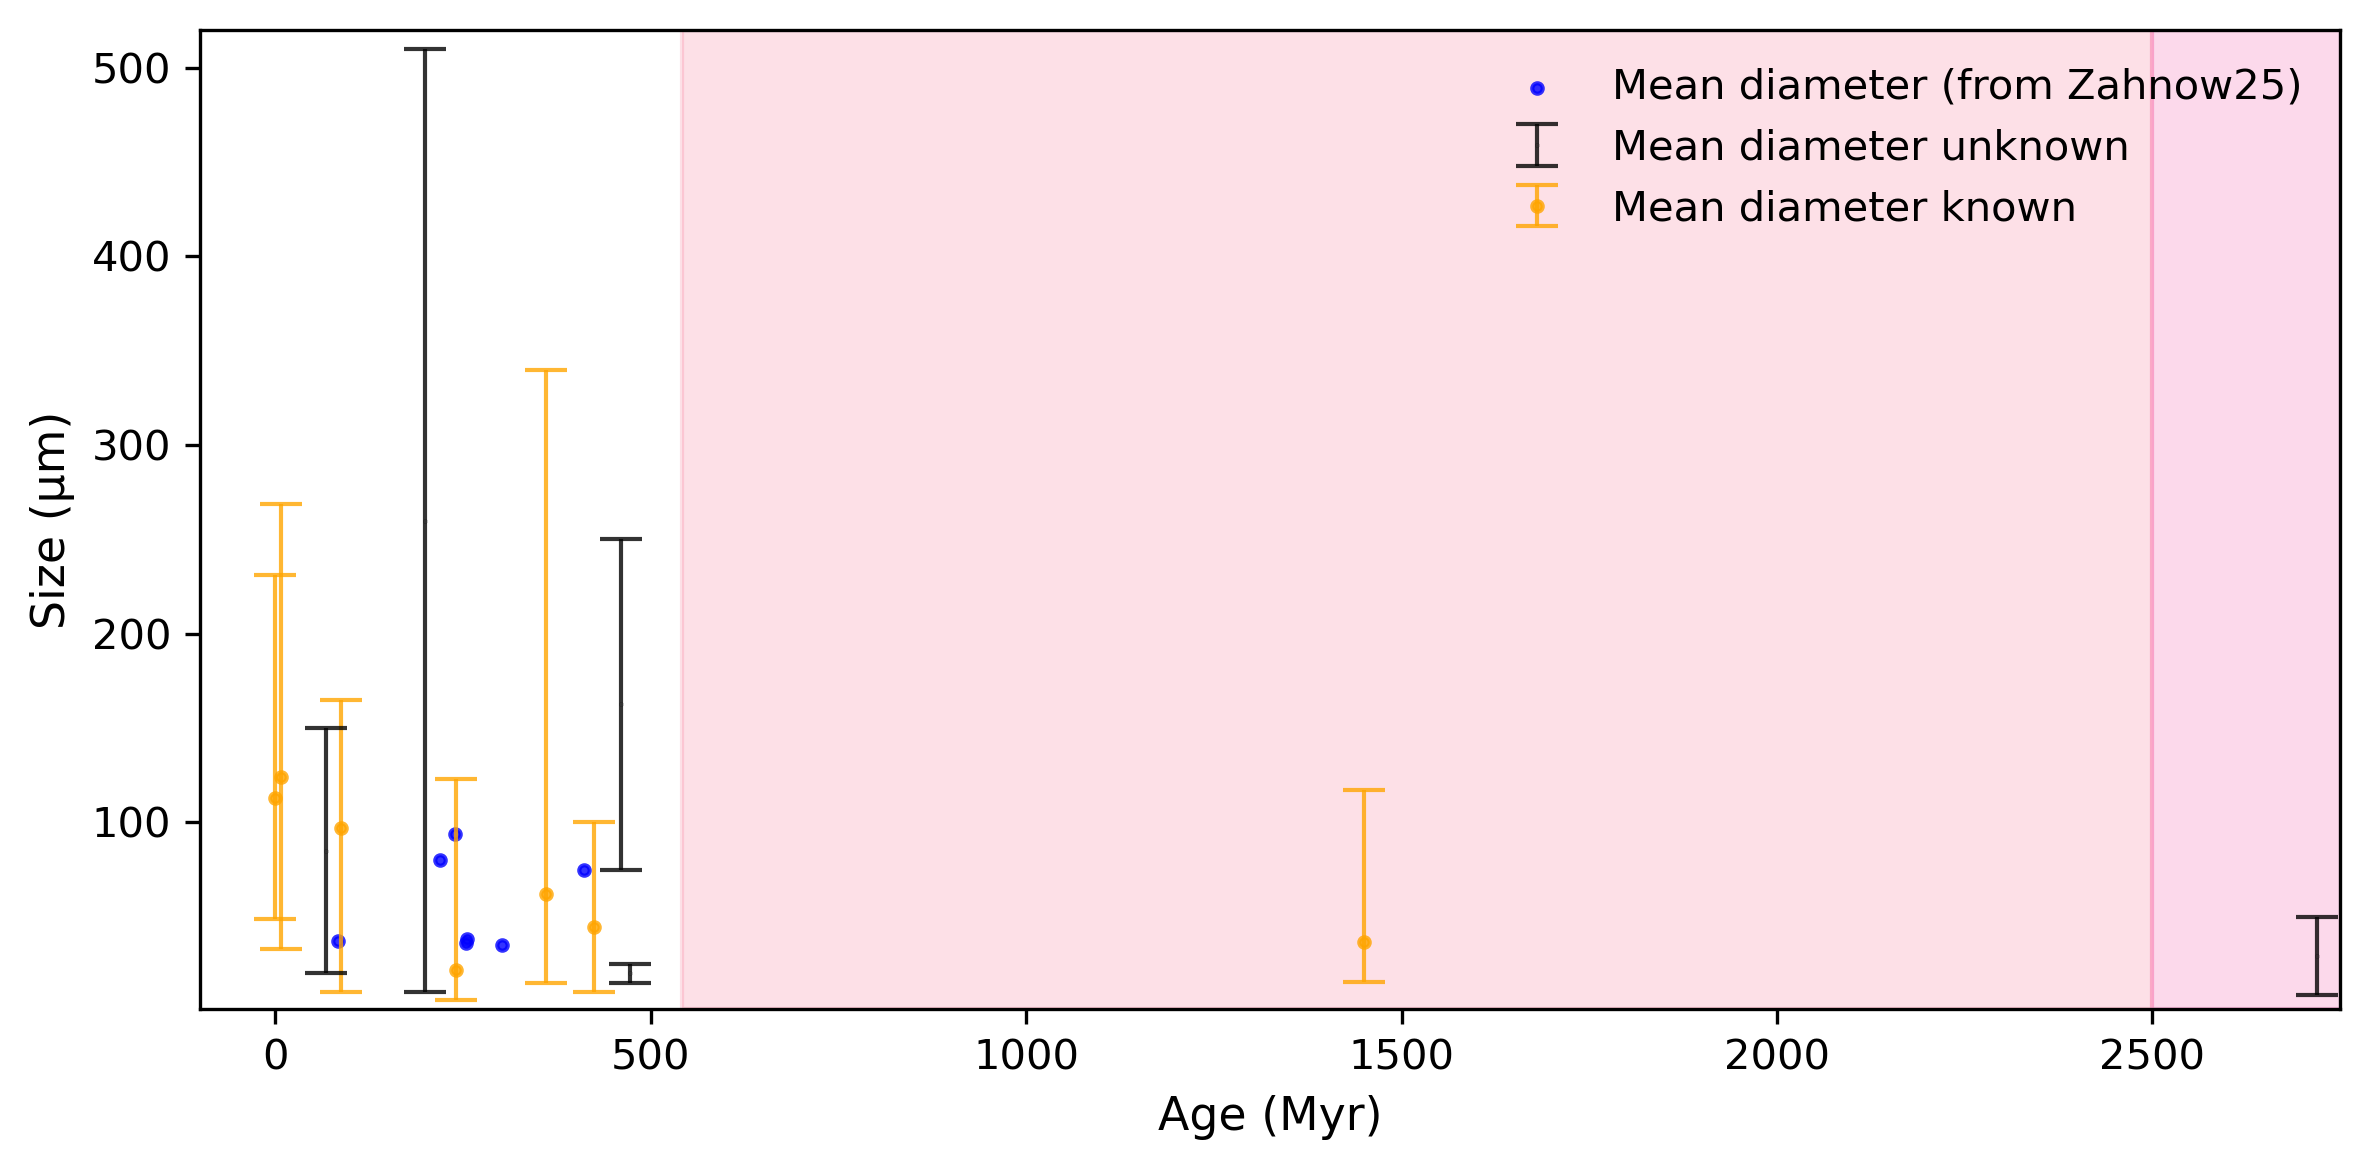

In [11]:

Mean = np.zeros(N)
flag = np.zeros(N)
Lower = np.zeros(N)
Upper = np.zeros(N)
for i in range(0,N):
    if mean[i] > 0:
        Mean[i] = mean[i]
        flag[i] = 1
    else:
        Mean[i] = (Size_min[i] + Size_max[i]) / 2

    Lower[i] = Mean[i] - Size_min[i]
    Upper[i] = Size_max[i] - Mean[i]
    print(Lower[i], Upper[i])
print(Mean)
fig = plt.figure(dpi=300,figsize = (8,4))
r1,r2,r3 = 0,0,0

for i in range(0,N):
    
    if flag[i] == 1 and Size_min[i] > 0: 
        col = 'orange'
        if r1 == 0:
            label = 'Mean diameter known'
            r1 = 1
        else:
            label = None
        
        plt.errorbar(Age[i], Mean[i], yerr=[[Lower[i]], [Upper[i]]], fmt='.', markersize = 5, capsize=5, alpha = 0.8, label = label, elinewidth=1,c = col)
    elif flag[i] == 1:
        if r2 == 0:
            label = 'Mean diameter (from Zahnow25)'
            r2 = 1
        else:
            label = None
        col = 'blue'
        plt.scatter(Age[i], Mean[i], s=25, marker='.', c=col,label = label, alpha = 0.8)
    elif flag[i] == 0:
        if r3 == 0:
            label = 'Mean diameter unknown'
            r3 = 1
        else:
            label = None
        col = 'k'
        plt.errorbar(Age[i], Mean[i], yerr=[[Lower[i]], [Upper[i]]], fmt='.', label = label, markersize = 0.1, alpha = 0.8,capsize=5, elinewidth=1,c = col)
plt.xlabel('Age (Myr)',fontsize = 11)
plt.xticks(np.arange(0,2800,500))
plt.ylabel('Size (µm)',fontsize = 11)
plt.legend(loc = 1,frameon = False, fontsize = 10)
plt.axvspan(541, 2500, color='#F73563', alpha=0.15)
plt.axvspan(2500, 2800, color='#F0027F', alpha=0.15)
plt.xlim(-100,2750)
plt.ylim(1, 520)
plt.tight_layout()
fig.savefig('size.pdf')